# Question 2

**Name:** Hafsah Zulqarnain  ·  **Student ID:** 25280045  · 

### Fixed protocol
- 8,000 training / 1,000 validation / 1,000 test videos, split by index; pixels in [0,1].
- Five inputs, five generated predictions, nine recurrent steps, no teacher forcing or detached feedback.
- Adam, learning rate 0.001, batch 32, 30 epochs, seeds 0 and 1; no scheduler or extra A–C layers.
- Training loss averages available horizons within each video, then averages videos.
- Default evaluation: start frame 1. Across speeds compare the first two horizons.
- Model D: dilation 2 in both recurrent convolutions, unchanged weights count; final model: symmetrised D. The optional D+B experiment is not needed for this implementation.
- Report errors to three significant figures; below 1e-3 use scientific notation. Wrapped consistency gaps always use scientific notation.



In [ ]:
import os, sys, json, time, random, platform, hashlib, shutil, subprocess
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import imageio.v2 as imageio
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.datasets import MovingMNIST
from tqdm.auto import tqdm
from IPython.display import display, Markdown, Image

ROOT = Path("motion_or_memory").resolve()
DATA = ROOT / "data"
OUT = ROOT / "results"
CKPT = ROOT / "checkpoints"
for folder in [DATA, OUT, CKPT, OUT/'tables', OUT/'figures', OUT/'gifs', OUT/'metrics', ROOT/'predictions']:
    folder.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE, EPOCHS, LR, SEEDS = 32, 30, 1e-3, (0, 1)
PROTOCOL_VERSION = 'q2-v1-dilation2'

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def sync():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

HARDWARE = {'device': str(DEVICE), 'gpu': torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
            'cpu': platform.processor() or platform.machine(), 'platform': platform.platform(),
            'python': sys.version, 'torch': torch.__version__, 'torchvision': torchvision.__version__,
            'opencv': cv2.__version__, 'numpy': np.__version__}
(OUT/'hardware.json').write_text(json.dumps(HARDWARE, indent=2))
print(json.dumps(HARDWARE, indent=2))
if DEVICE.type != 'cuda': print('CPU selected: full training will be slow. A CUDA GPU is recommended.')


{
  "device": "cuda",
  "gpu": "Tesla T4",
  "cpu": "x86_64",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "opencv": "5.0.0",
  "numpy": "2.1.3"
}


## 1. Setup
Frame labels in the assignment are **1-based**. Tensor indices and the synthetic marker coordinates are **0-based**. All functions below operate on the last two axes, so the same transformations work for frames, videos and batches.

The eight group elements are `(a, mirror_after_rotation)`: rotate by `a × 90°` first, then optionally mirror. For reflected elements the inverse is the same transformation; for pure rotations it is the reverse rotation.


In [ ]:
GROUP = [(a, m) for m in (False, True) for a in range(4)]
IDENTITY, MIRROR, ROTATION = (0, False), (0, True), (1, False)
def transform(x, g):
    a, mirrored = g
    z = torch.rot90(x, a, dims=(-2, -1))
    return z.flip(-1) if mirrored else z

def inverse_transform(x, g):
    a, mirrored = g
    return transform(x, g) if mirrored else torch.rot90(x, -a, dims=(-2, -1))

def allowed_starts(k, speed_augmented):
    if not speed_augmented:
        assert k == 1
        return list(range(1, 12))
    assert k in (1, 2, 3)
    return list(range(1, 20 - 6*k + 1))

def make_window(video, t=1, k=1):
    assert video.shape == (20, 1, 64, 64)
    assert isinstance(t, int) and isinstance(k, int) and t >= 1 and k >= 1
    inputs = [t-1 + j*k for j in range(5)]
    targets = [t-1 + j*k for j in range(5, 10) if t-1 + j*k < 20]
    assert inputs[-1] < 20 and len(targets) >= 2
    x = video[inputs]
    y = video.new_zeros((5, 1, 64, 64))
    mask = torch.zeros(5, dtype=torch.bool)
    y[:len(targets)] = video[targets]
    mask[:len(targets)] = True
    return x, y, mask

def save_table(df, number):
    display(Markdown(f'**Table {number}**'))
    display(df)
    df.to_csv(OUT/'tables'/f'table_{number}.csv', index=False)
    (OUT/'tables'/f'table_{number}.html').write_text(df.to_html(index=False))

seed_all(0)
x = torch.rand(20, 1, 64, 64)
p = torch.zeros_like(x); p[7, 0, 10, 20] = 1
checks = [('a', transform(transform(x, MIRROR), MIRROR), x),
          ('b', torch.rot90(x, 4, (-2,-1)), x),
          ('c', transform(transform(transform(x, MIRROR), ROTATION), MIRROR), inverse_transform(x, ROTATION))]
rows = []
for name, lhs, rhs in checks:
    gap = (lhs-rhs).abs().max().item()
    equal = torch.equal(lhs, rhs)
    assert gap == 0 and equal
    rows.append({'Check':name,'Expected':'max difference 0; torch.equal=True','Yours':f'{gap:g}; torch.equal={equal}'})
for name, g, expected in [('d', MIRROR, (7,10,43)), ('e',ROTATION,(7,43,10))]:
    idx = transform(p,g).nonzero()[0].tolist()
    actual = (idx[0],idx[2],idx[3])
    assert actual == expected
    rows.append({'Check':name,'Expected':str(expected),'Yours':str(actual)})
labels = torch.arange(1,21).view(20,1,1,1).expand(20,1,64,64)
expected = {1:([1,2,3,4,5],[6,7,8,9,10]), 2:([1,3,5,7,9],[11,13,15,17,19]), 3:([1,4,7,10,13],[16,19])}
for k, name in zip((1,2,3),('f','g','h')):
    xx,yy,mask = make_window(labels,1,k)
    actual = (xx[:,0,0,0].tolist(), yy[mask,0,0,0].tolist())
    assert actual == expected[k]
    rows.append({'Check':name,'Expected':str(expected[k]),'Yours':str(actual)})
for g in GROUP:
    assert torch.equal(inverse_transform(transform(x,g),g),x)
assert [len(allowed_starts(k,True)) for k in (1,2,3)] == [14,8,2]
save_table(pd.DataFrame(rows),1)


**Table 1**

,Check,Expected,Yours
0,a,max difference 0; torch.equal=True,0; torch.equal=True
1,b,max difference 0; torch.equal=True,0; torch.equal=True
2,c,max difference 0; torch.equal=True,0; torch.equal=True
3,d,"(7, 10, 43)","(7, 10, 43)"
4,e,"(7, 43, 10)","(7, 43, 10)"
5,f,"([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])","([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])"
6,g,"([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])","([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])"
7,h,"([1, 4, 7, 10, 13], [16, 19])","([1, 4, 7, 10, 13], [16, 19])"


In [ ]:
raw = MovingMNIST(root=str(DATA), split=None, download=True)
assert len(raw) == 10000
assert tuple(raw[0].shape) == (20,1,64,64)
TRAIN_IDS = list(range(0,8000))
VAL_IDS = list(range(8000,9000))
TEST_IDS = list(range(9000,10000))
def video(index):
    return raw[int(index)].to(torch.float32).div(255.0)
assert 0 <= video(0).min() and video(0).max() <= 1
print('Videos:',len(raw),'| shape:',raw[0].shape,'| splits:',len(TRAIN_IDS),len(VAL_IDS),len(TEST_IDS))


100%|██████████| 819M/819M [00:28<00:00, 29.1MB/s]


Videos: 10000 | shape: torch.Size([20, 1, 64, 64]) | splits: 8000 1000 1000


### What motion is present in training?
Use exactly 50 training videos × 19 adjacent pairs. The mask requires intensities **above** 0.2 in both frames and flow magnitude **above** 0.5. Both histograms show fraction of kept pixels, not density and not raw counts. Optical flow is an estimate, not ground-truth digit velocity.


Figure 1: optical flow:   0%|          | 0/50 [00:00<?, ?it/s]

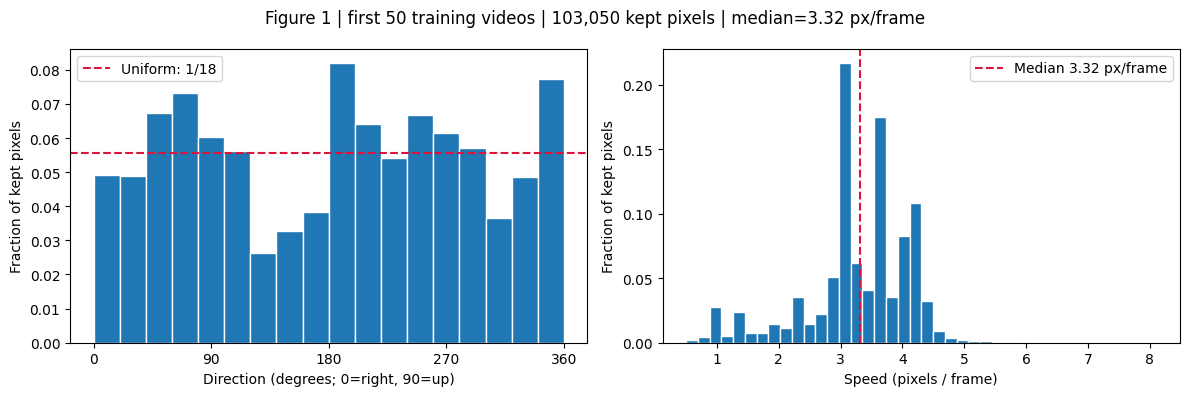

Typical sampled displacement at 1x, 2x, 3x: [3.318, 6.635, 9.953]


In [ ]:
def compute_training_flow():
    angles, speeds = [], []
    for idx in tqdm(range(50), desc='Figure 1: optical flow'):
        frames = (video(idx).numpy()[:,0] * 255).round().astype(np.uint8)
        for s in range(19):
            prev, nxt = frames[s], frames[s+1]
            flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
            dx,dy = flow[...,0],flow[...,1]
            mag = np.hypot(dx,dy)
            keep = (prev > 51) & (nxt > 51) & (mag > 0.5)
            angles.append(np.degrees(np.arctan2(-dy[keep],dx[keep])) % 360)
            speeds.append(mag[keep])
    return np.concatenate(angles),np.concatenate(speeds)

flow_angles, flow_speeds = compute_training_flow()
median_speed = float(np.median(flow_speeds)); n_kept = len(flow_speeds)
np.savez_compressed(OUT/'metrics'/'figure1_flow.npz', angles=flow_angles, speeds=flow_speeds)
fig,ax=plt.subplots(1,2,figsize=(12,4))
w=np.ones(n_kept)/n_kept
ax[0].hist(flow_angles,bins=np.arange(0,361,20),weights=w,edgecolor='white')
ax[0].axhline(1/18,color='crimson',linestyle='--',label='Uniform: 1/18')
ax[0].set(xlabel='Direction (degrees; 0=right, 90=up)',ylabel='Fraction of kept pixels',xticks=np.arange(0,361,90))
ax[0].legend()
ax[1].hist(flow_speeds,bins=40,weights=w,edgecolor='white')
ax[1].axvline(median_speed,color='crimson',linestyle='--',label=f'Median {median_speed:.3g} px/frame')
ax[1].set(xlabel='Speed (pixels / frame)',ylabel='Fraction of kept pixels'); ax[1].legend()
fig.suptitle(f'Figure 1 | first 50 training videos | {n_kept:,} kept pixels | median={median_speed:.3g} px/frame')
fig.tight_layout(); fig.savefig(OUT/'figures'/'figure_1.png',dpi=180,bbox_inches='tight'); plt.show()
print('Typical sampled displacement at 1x, 2x, 3x:', [round(median_speed*k,3) for k in (1,2,3)])


### Q2.1

> Based on Figure 1(a), would mirrored and rotated trajectories already be familiar to a model trained on this data? (Hint: how would the direction histogram change if every training video were mirrored? If every video were rotated by 90°?) From Figure 1(b), what is a typical speed, and what do 2× and 3× correspond to in pixels per frame? Optical flow is unreliable where digits overlap; could that bias your histograms enough to change your answer?

**Answer:**

Figure 1(a) shows that the digits move in many directions. Therefore, mirrored and rotated movements should not be completely new to the model.

Figure 1(b) shows that the usual speed is about 3.32 pixels per frame.
- \(2 X) speed: about 6.64 pixels per frame
- \(3 X) speed: about 9.96 pixels per frame
When digits overlap, optical flow may make some mistakes because the digits are mixed together. However, there are many data points, so this probably does not change the result.

### Q2.2

> For each transformation, does it change the motion statistics, the digit appearance, or both? Why does this make the three of them useful as a controlled experiment?

**Answer:**

- Mirror: Changes the movement direction and the digit’s appearance.
- Rotation: Changes the movement direction and the digit’s appearance.
- Speed-up: Changes the movement speed and distance travelled, but keeps the digit’s appearance the same.
These transformations are useful because they test different abilities separately. Mirror and rotation test whether the model can handle changed digit appearances and directions. Speed-up tests whether the model can predict faster movement.

## 2. Baseline: ConvLSTM
### Architecture, recurrence and training utilities
A–C use the exact baseline. D changes only recurrent-convolution dilation (2 instead of 1) and matching padding.

$$[i,f,o,g]=\mathrm{Conv}([u_\tau,h_{\tau-1}]),\quad c_\tau=\sigma(f)c_{\tau-1}+\sigma(i)\tanh(g),\quad h_\tau=\sigma(o)\tanh(c_\tau).$$

A frame is folded from `(1,64,64)` to `(16,16,16)`; two 64-channel ConvLSTMs precede a 64→16 output convolution, pixel shuffle and sigmoid. Nine steps are executed; outputs of steps 5–9 are returned. Feedback predictions remain in the autograd graph.

Per-video masked loss:
$$L=\frac1B\sum_b\frac{\sum_h m_{bh}\operatorname{MSE}_{bh}}{\sum_h m_{bh}}.$$


In [ ]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_channels, hidden_channels=64, dilation=1):
        super().__init__()
        self.hidden_channels=hidden_channels
        self.gates=nn.Conv2d(in_channels+hidden_channels,4*hidden_channels,3,
                             padding=dilation,dilation=dilation,bias=True)
    def forward(self,u,state):
        h,c=state
        i,f,o,g=self.gates(torch.cat([u,h],dim=1)).chunk(4,dim=1)
        c=torch.sigmoid(f)*c+torch.sigmoid(i)*torch.tanh(g)
        h=torch.sigmoid(o)*torch.tanh(c)
        return h,c

class Forecaster(nn.Module):
    def __init__(self,dilation=1):
        super().__init__()
        self.cell1=ConvLSTMCell(16,64,dilation)
        self.cell2=ConvLSTMCell(64,64,dilation)
        self.head=nn.Conv2d(64,16,1,bias=True)
    def forward(self,x):
        assert x.ndim==5 and x.shape[1:]==(5,1,64,64)
        z=x.new_zeros(x.shape[0],64,16,16)
        s1=(z,z.clone()); s2=(z.clone(),z.clone())
        outputs=[]
        for step in range(9):
            frame=x[:,step] if step<5 else pred
            folded=F.pixel_unshuffle(frame,4)
            s1=self.cell1(folded,s1)
            s2=self.cell2(s1[0],s2)
            pred=torch.sigmoid(F.pixel_shuffle(self.head(s2[0]),4))
            if step>=4: outputs.append(pred)
        return torch.stack(outputs,dim=1)

class Reference(nn.Module):
    def __init__(self,kind): super().__init__(); self.kind=kind
    def forward(self,x):
        return torch.zeros_like(x) if self.kind=='Blank' else x[:,-1:].expand(-1,5,-1,-1,-1)

class Symmetrised(nn.Module):
    def __init__(self,base): super().__init__(); self.base=base
    def forward(self,x):
        total=None
        for g in GROUP:
            prediction=inverse_transform(self.base(transform(x,g)),g)
            total=prediction if total is None else total+prediction
        return total/len(GROUP)

def parameter_count(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)
def build_model(name):
    assert name in ('A','B','C','D')
    return Forecaster(dilation=2 if name=='D' else 1)

def masked_mse(pred,y,mask):
    per_h=(pred-y).square().mean(dim=(2,3,4))
    return ((per_h*mask).sum(1)/mask.sum(1)).mean()

assert parameter_count(build_model('A'))==480784
assert parameter_count(build_model('D'))<=721176
print('Parameters A–D:',{name:parameter_count(build_model(name)) for name in 'ABCD'})

class WindowDataset(Dataset):
    def __init__(self,ids,model_name=None,k=1):
        self.ids=list(ids); self.model_name=model_name; self.k=k
    def __len__(self): return len(self.ids)
    def __getitem__(self,index):
        idx=self.ids[index]
        if self.model_name is None:
            k,t=self.k,1
        else:
            speed_aug=self.model_name in ('C','D')
            k=int(torch.randint(1,4,()).item()) if speed_aug else 1
            starts=allowed_starts(k,speed_aug)
            t=starts[int(torch.randint(len(starts),()).item())]
        x,y,mask=make_window(video(idx),t,k)
        if self.model_name=='B':
            g=GROUP[int(torch.randint(8,()).item())]
            x,y=transform(x,g),transform(y,g)
        return x,y,mask,idx

def make_loader(ids,model_name=None,k=1,generator=None):
    return DataLoader(WindowDataset(ids,model_name,k),batch_size=BATCH_SIZE,
                      shuffle=model_name is not None,num_workers=0,
                      pin_memory=DEVICE.type=='cuda',generator=generator)


Parameters A–D: {'A': 480784, 'B': 480784, 'C': 480784, 'D': 480784}


##### No of weights for all 4 models remain same

In [ ]:
def protocol(name,seed):
    return {'version':PROTOCOL_VERSION,'name':name,'seed':seed,'epochs':EPOCHS,
            'batch_size':BATCH_SIZE,'lr':LR,'dilation':2 if name=='D' else 1,
            'train_indices':[0,7999],'precision':'float32'}

def checkpoint_path(name,seed): return CKPT/f'{name}_seed{seed}.pt'
def trusted_load(path):
    return torch.load(path,map_location=DEVICE,weights_only=False)

def train_model(name,seed):
    cfg=protocol(name,seed); path=checkpoint_path(name,seed)
    seed_all(seed)
    generator=torch.Generator().manual_seed(seed)
    model=build_model(name).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=LR)
    history=[]; start_epoch=0; hardware_segments=[]
    if path.exists():
        ck=trusted_load(path)
        assert ck['protocol']==cfg, 'Checkpoint protocol differs. Use a new ROOT for new experiments.'
        model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
        history=ck['history']; start_epoch=ck['epoch']; hardware_segments=ck.get('hardware_segments',[])
        torch.set_rng_state(ck['torch_rng'].cpu())
        generator.set_state(ck['loader_rng'].cpu())
        if DEVICE.type=='cuda' and ck['cuda_rng'] is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in ck['cuda_rng']])
        random.setstate(ck['python_rng']); np.random.set_state(ck['numpy_rng'])
        print(f'{name} seed {seed}: restored epoch {start_epoch}/{EPOCHS}')
    loader=make_loader(TRAIN_IDS,name,generator=generator)
    if start_epoch<EPOCHS:
        hardware_segments.append({'first_epoch':start_epoch+1,'hardware':HARDWARE})
    for epoch in range(start_epoch,EPOCHS):
        model.train(); total=0.; n=0
        sync(); started=time.perf_counter()
        for x,y,mask,_ in tqdm(loader,desc=f'{name} seed {seed}, epoch {epoch+1}/{EPOCHS}',leave=False):
            x=x.to(DEVICE); y=y.to(DEVICE); mask=mask.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss=masked_mse(model(x),y,mask)
            loss.backward(); optimizer.step()
            total+=loss.item()*x.shape[0]; n+=x.shape[0]
        sync(); seconds=time.perf_counter()-started
        history.append({'epoch':epoch+1,'training_loss':total/n,'seconds':seconds})
        state={'protocol':cfg,'epoch':epoch+1,'model':model.state_dict(),'optimizer':optimizer.state_dict(),
               'history':history,'hardware_segments':hardware_segments,
               'torch_rng':torch.get_rng_state(),'loader_rng':generator.get_state(),
               'cuda_rng':torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else None,
               'python_rng':random.getstate(),'numpy_rng':np.random.get_state()}
        temp=path.with_suffix('.tmp'); torch.save(state,temp); temp.replace(path)
        pd.DataFrame(history).to_csv(OUT/'metrics'/f'{name}_seed{seed}_training.csv',index=False)
        print(f'{name}/{seed}: epoch {epoch+1:02d}, loss={total/n:.6g}, {seconds:.1f}s')
    return model.eval()

def load_model(name,seed):
    ck=trusted_load(checkpoint_path(name,seed))
    assert ck['protocol']==protocol(name,seed) and ck['epoch']==EPOCHS, 'Need final-epoch weights.'
    model=build_model(name).to(DEVICE); model.load_state_dict(ck['model'])
    return model.eval()

@torch.no_grad()
def evaluate(model,k=1,spatial=False,ids=None):
    model.eval(); collected={key:[] for key in ['ids','mse']+(['CM','EM','CR','ER'] if spatial else [])}
    for x,y,mask,idx in make_loader(TEST_IDS if ids is None else ids,k=k):
        x=x.to(DEVICE); y=y.to(DEVICE); mask=mask.to(DEVICE)
        pred=model(x)
        err=(pred-y).square().mean((2,3,4)).masked_fill(~mask,float('nan'))
        collected['ids'].append(idx.numpy()); collected['mse'].append(err.cpu().numpy())
        if spatial:
            assert k==1
            for label,g in [('M',MIRROR),('R',ROTATION)]:
                transformed=model(transform(x,g))
                consistency=(transformed-transform(pred,g)).square().mean((1,2,3,4))
                accuracy=(transformed-transform(y,g)).square().mean((1,2,3,4))
                collected['C'+label].append(consistency.cpu().numpy())
                collected['E'+label].append(accuracy.cpu().numpy())
    return {key:np.concatenate(value) for key,value in collected.items()}

@torch.no_grad()
def inference_seconds(model):
    model.eval()
    warm=next(iter(make_loader(TEST_IDS)))[0].to(DEVICE)
    model(warm); sync()
    elapsed=0.
    for x,_,_,_ in make_loader(TEST_IDS):
        x=x.to(DEVICE); sync()
        start=time.perf_counter(); prediction=model(x); sync()
        elapsed+=time.perf_counter()-start
        del prediction
    return elapsed

def save_evaluation(label,seed,k,result):
    np.savez_compressed(OUT/'metrics'/f'{label}_seed{seed}_speed{k}.npz',**result)
def read_evaluation(label,seed,k):
    with np.load(OUT/'metrics'/f'{label}_seed{seed}_speed{k}.npz') as z:
        return {key:z[key] for key in z.files}

def error_summary(result):
    mse=result['mse'].mean(axis=0)
    out={f'MSE{h+1}':float(mse[h]) for h in range(5)}
    out['E2']=float(result['mse'][:,:2].mean())
    out['E5']=float(result['mse'].mean()) if np.isfinite(result['mse']).all() else np.nan
    for key in ('CM','EM','CR','ER'):
        if key in result: out[key]=float(result[key].mean())
    return out

def fmt(value,scientific=False):
    if not np.isfinite(value): return '—'
    if scientific or (value!=0 and abs(value)<1e-3): return f'{value:.2e}'
    return f'{value:.3g}'
def pair(values,scientific=False,integer=False):
    assert len(values)==2
    f=(lambda x:f'{x:,.0f}') if integer else (lambda x:fmt(x,scientific))
    return f'{f(np.mean(values))} ({f(values[0])}, {f(values[1])})'


### Train A
This cell performs two 30-epoch runs or resumes their checkpoints. Epoch timing covers the training pass, including sampling/data transfer, and excludes checkpoint writing and dataset download. Hardware for each resumed segment is recorded; use the same hardware across models for meaningful comparisons.


In [ ]:
for seed in SEEDS:
    trained=train_model('A',seed)
    del trained
    if DEVICE.type=='cuda': torch.cuda.empty_cache()


A seed 0, epoch 1/30:   0%|          | 0/250 [00:00<?, ?it/s]

A/0: epoch 01, loss=0.0460811, 15.2s


A seed 0, epoch 2/30:   0%|          | 0/250 [00:00<?, ?it/s]

A/0: epoch 02, loss=0.0396887, 12.6s


A seed 0, epoch 3/30:   0%|          | 0/250 [00:00<?, ?it/s]

...

A/1: epoch 28, loss=0.0225132, 13.5s


A seed 1, epoch 29/30:   0%|          | 0/250 [00:00<?, ?it/s]

A/1: epoch 29, loss=0.0223292, 13.5s


A seed 1, epoch 30/30:   0%|          | 0/250 [00:00<?, ?it/s]

A/1: epoch 30, loss=0.0221016, 13.5s


In [ ]:
for seed in SEEDS:
    model=load_model('A',seed)
    save_evaluation('A',seed,1,evaluate(model))
    del model
for name in ('Blank','Copy-last'):
    save_evaluation(name,0,1,evaluate(Reference(name).to(DEVICE)))
rows=[]
for name in ('A','Blank','Copy-last'):
    seeds=SEEDS if name=='A' else (0,)
    summaries=[error_summary(read_evaluation(name,s,1)) for s in seeds]
    row={'Model':name}
    for key in [f'MSE{h}' for h in range(1,6)]+['E5']:
        vals=[v[key] for v in summaries]
        row[key]=pair(vals) if name=='A' else fmt(vals[0])
    row['Trainable parameters']=pair([480784,480784],integer=True) if name=='A' else '0'
    rows.append(row)
save_table(pd.DataFrame(rows),2)


**Table 2**

,Model,MSE1,MSE2,MSE3,MSE4,MSE5,E5,Trainable parameters
0,A,"0.0171 (0.0171, 0.0171)","0.0205 (0.0205, 0.0205)","0.0227 (0.0228, 0.0226)","0.0244 (0.0246, 0.0242)","0.026 (0.0263, 0.0258)","0.0221 (0.0223, 0.022)","480,784 (480,784, 480,784)"
1,Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
2,Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


### Qualitative plotting helpers
Moving MNIST does not provide overlap labels. The candidate search below uses connected components **only to propose clips**; disconnected strokes can fool this heuristic. Inspect all displayed true frames before confirming. Candidate sheets are selection aids, not numbered report figures. Use dataset indices 9000–9999 throughout.


Possible overlap clips: [9000, 9001, 9002, 9003]


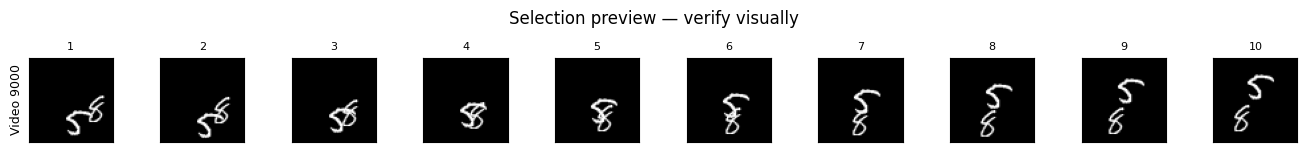

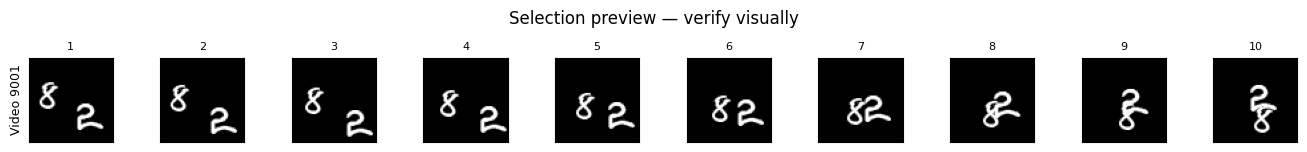

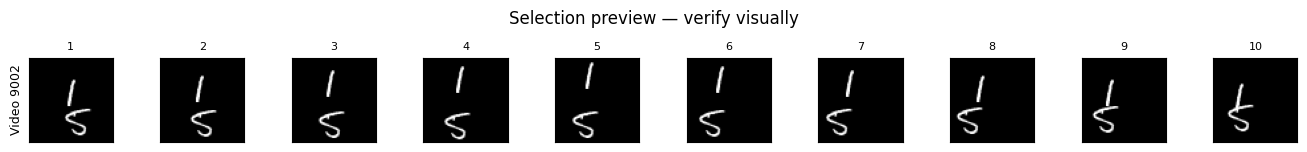

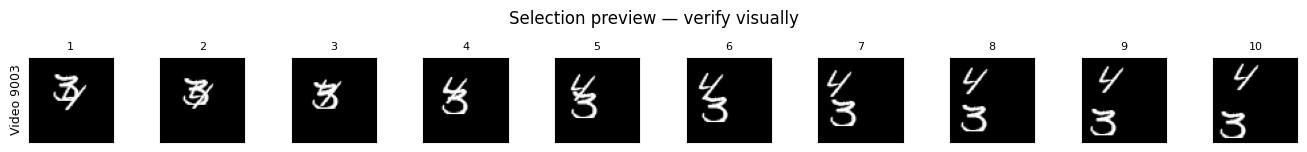

In [ ]:
@torch.no_grad()
def predict_video(model,idx,k=1,g=IDENTITY):
    x,y,mask=make_window(video(idx),1,k)
    pred=model(transform(x,g).unsqueeze(0).to(DEVICE)).cpu()[0]
    return x,y,mask,pred

def frame_grid(rows,labels,title,path=None,column_labels=None):
    cols=len(rows[0]); fig,axes=plt.subplots(len(rows),cols,figsize=(cols*1.35,len(rows)*1.5),squeeze=False)
    for r,frames in enumerate(rows):
        for c,frame in enumerate(frames):
            ax=axes[r,c]; ax.imshow(np.asarray(frame).squeeze(),cmap='gray',vmin=0,vmax=1)
            ax.set_xticks([]);ax.set_yticks([])
            if c==0: ax.set_ylabel(labels[r],fontsize=9)
            if r==0 and column_labels: ax.set_title(column_labels[c],fontsize=8)
    fig.suptitle(title,fontsize=12);fig.tight_layout()
    if path: fig.savefig(path,dpi=150,bbox_inches='tight')
    plt.show();return fig

def large_component_count(frame):
    binary=(frame.squeeze().numpy()>0.2).astype(np.uint8)
    n,_,stats,_=cv2.connectedComponentsWithStats(binary,connectivity=8)
    return int((stats[1:,cv2.CC_STAT_AREA]>=15).sum())

def suggest_candidates(kind,limit=4):
    result=[]
    displayed=sorted(set([1,2,3,4,5,6,7,9,10,11,13,16,19]))
    for idx in TEST_IDS:
        v=video(idx)
        counts=[large_component_count(v[t-1]) for t in (range(1,11) if kind=='overlap' else displayed)]
        ok=(1 in counts and 2 in counts) if kind=='overlap' else all(c==2 for c in counts)
        if ok: result.append(idx)
        if len(result)>=limit: break
    return result

def preview_candidates(ids,frames):
    for idx in ids:
        frame_grid([video(idx)[[f-1 for f in frames]]],[f'Video {idx}'],
                   'Selection preview — verify visually',column_labels=[str(f) for f in frames])

OVERLAP_CANDIDATES=suggest_candidates('overlap')
print('Possible overlap clips:',OVERLAP_CANDIDATES)
preview_candidates(OVERLAP_CANDIDATES,list(range(1,11)))


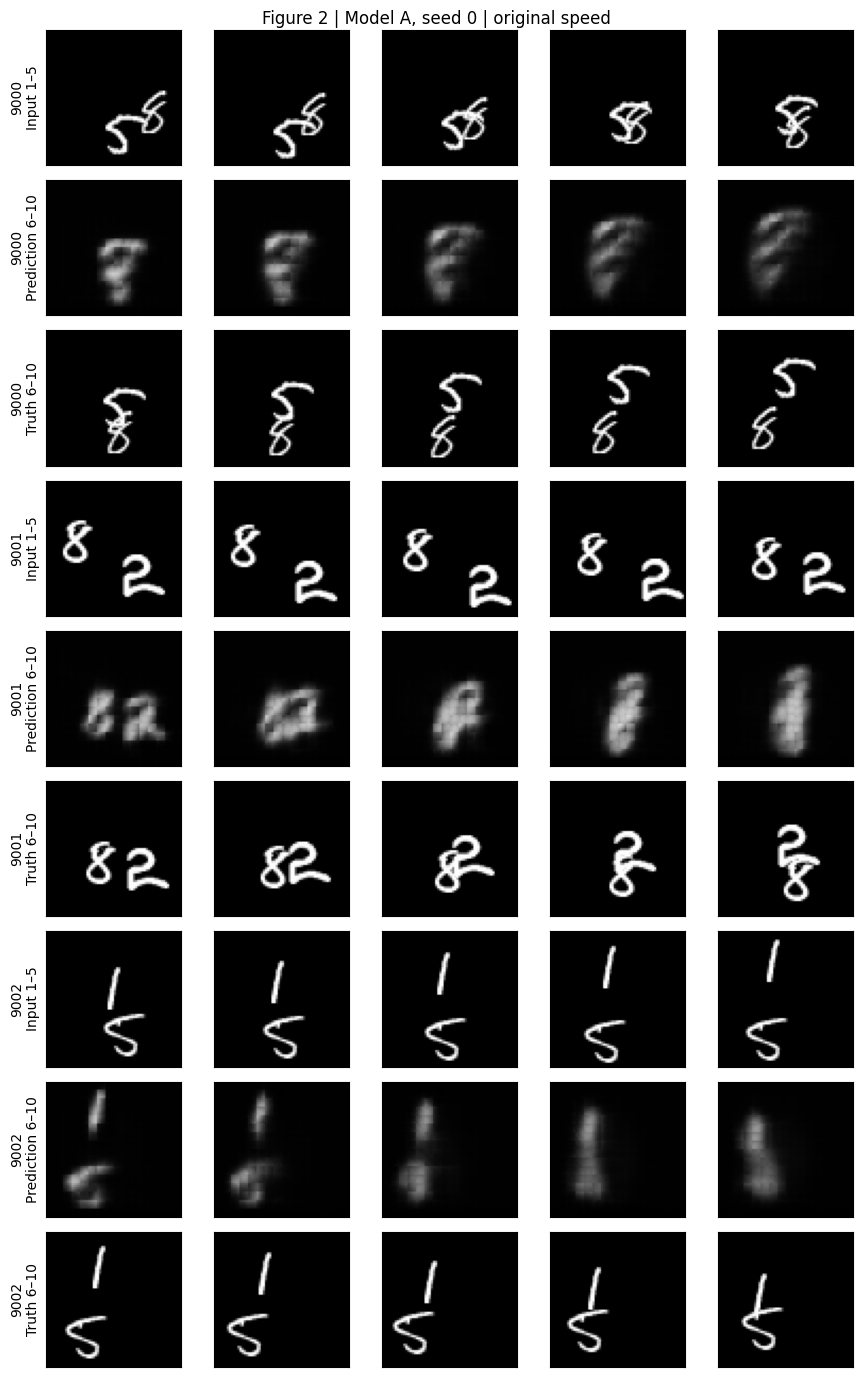

69

In [ ]:
FIG2_IDS = [9000, 9001,9002]
FIG2_OVERLAP_ID =9001
FIG2_OVERLAP_CONFIRMED = True
if not (FIG2_OVERLAP_CONFIRMED and FIG2_OVERLAP_ID in FIG2_IDS):
    raise ValueError('Inspect the previews; choose Figure 2 IDs, an overlapping video, and set confirmation True.')
assert len(set(FIG2_IDS))==3 and all(i in TEST_IDS for i in FIG2_IDS)
a0=load_model('A',0)
fig,axes=plt.subplots(9,5,figsize=(9,14))
for block,idx in enumerate(FIG2_IDS):
    x,y,mask,pred=predict_video(a0,idx)
    for j,(frames,label) in enumerate([(x,'Input 1–5'),(pred,'Prediction 6–10'),(y,'Truth 6–10')]):
        for c in range(5):
            ax=axes[block*3+j,c];ax.imshow(frames[c,0],cmap='gray',vmin=0,vmax=1)
            ax.set_xticks([]);ax.set_yticks([])
            if c==0:ax.set_ylabel(f'{idx}\n{label}')
fig.suptitle('Figure 2 | Model A, seed 0 | original speed');fig.tight_layout()
fig.savefig(OUT/'figures'/'figure_2.png',dpi=180,bbox_inches='tight');plt.show()
(OUT/'figure2_selection.json').write_text(json.dumps({'ids':FIG2_IDS,'overlap_id':FIG2_OVERLAP_ID},indent=2))


### Q2.3

> Estimate model A’s reach in original pixels per time step, using the conventions above. Walk through your reasoning from the patch size, kernel sizes, number of layers and the recurrence. There is no formula to look up for this.


**Answer:**

Model A first uses pixel_unshuffle(4), which changes the \(64 x 64\) image into a \(16 x16\) grid. Therefore, one cell in this grid represents 4 original pixels. Each \(3 x 3\) convolution can move information by one grid cell in each direction. Since Model A has two ConvLSTM layers, the longest path passes through two convolutions, allowing information to travel \(2 x 4=8\) original pixels in one time step. The \(1 x 1\) output convolution, pixel unshuffle, and pixel shuffle do not increase this distance. Therefore, Model A’s reach is 8 original pixels per time step


### Q2.4

> Using Table 2 and Figure 2, how does model A compare with the two reference predictors, and how does its error grow over the five forecast horizons? What happens to its predictions when digits overlap?

**Answer:**

Model A performs better than both reference predictors. Its average error is \(E5=0.0221\), while Blank has \(E5=0.0426\) and Copy-last has \(E5=0.0641\). This shows that Model A has learned to predict the digits’ movement. Its error increases over the five forecast horizons, from \(0.0171\) at the first horizon to \(0.0260\) at the fifth horizon, because predicting farther into the future is more difficult. Figure 2 shows that the predictions become blurry over time. When the digits overlap, Model A has difficulty keeping their shapes separate and may merge them into one unclear shape.

### Q2.5

> Before you run any experiment in Testing the Baseline, write down your predictions: will model A pass the mirror test? The rotation test? At what speed should it break down, given your reach estimate and Figure 1? Include this answer in your report exactly as you first wrote it, even if it turns out to be wrong.


**Answer:**

I predict that Model A will not fully pass the mirror test because mirrored digits look different from the training digits. I also predict that it will perform worse on the rotation test because rotation changes the digit appearance more strongly. Based on the estimated reach of 8 pixels and the median speed of 3.32 pixels per frame, Model A should work reasonably at \(2X) speed, which is about 6.64 pixels per frame, but should start breaking down at \(3X) speed, which is about 9.96 pixels per frame and exceeds its reach.


## 3. Testing the Baseline
### Mirror and rotation
$$C_T=\operatorname{MSE}(f(TX),T(f(X))),\qquad E_T=\operatorname{MSE}(f(TX),T(Y)).$$
Always report both: exact consistency alone does not establish accurate forecasting.


In [ ]:
for name in ('A','Blank','Copy-last'):
    for seed in (SEEDS if name=='A' else (0,)):
        model=load_model(name,seed) if name=='A' else Reference(name).to(DEVICE)
        save_evaluation(name,seed,1,evaluate(model,spatial=True))
        del model
rows=[]
for name in ('A','Blank','Copy-last'):
    summaries=[error_summary(read_evaluation(name,s,1)) for s in (SEEDS if name=='A' else (0,))]
    row={'Model':name}
    for key in ('E5','CM','EM','CR','ER'):
        vals=[s[key] for s in summaries]; row[key]=pair(vals) if name=='A' else fmt(vals[0])
    rows.append(row)
save_table(pd.DataFrame(rows),3)


**Table 3**

,Model,E5,CM,EM,CR,ER
0,A,"0.0221 (0.0223, 0.022)","0.00174 (0.0018, 0.00169)","0.0228 (0.023, 0.0227)","0.00323 (0.00363, 0.00283)","0.0241 (0.0243, 0.0239)"
1,Blank,0.0426,0,0.0426,0,0.0426
2,Copy-last,0.0641,0,0.0641,0,0.0641


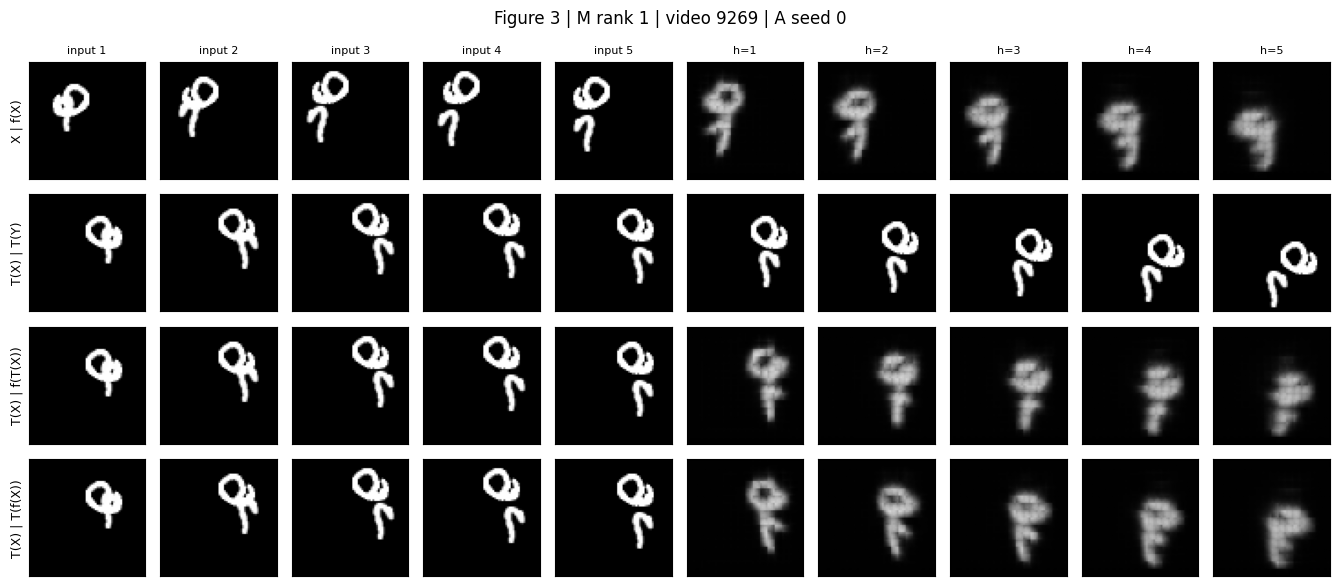

GIF path: `results/gifs/figure_3_M_1_video9269.gif`

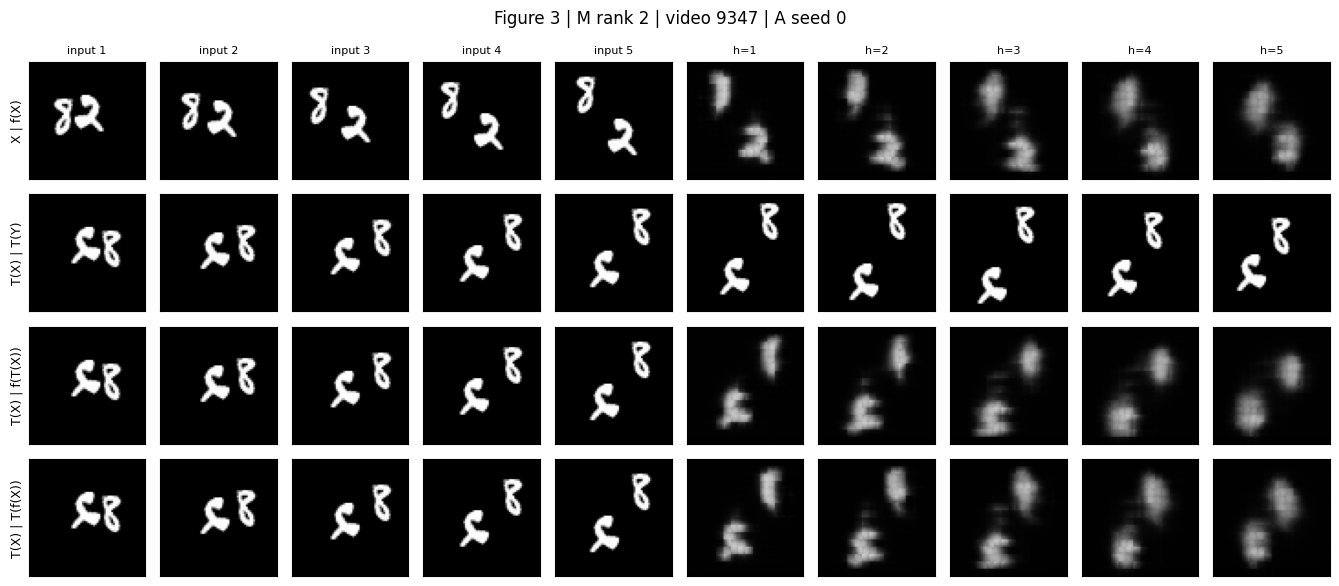

GIF path: `results/gifs/figure_3_M_2_video9347.gif`

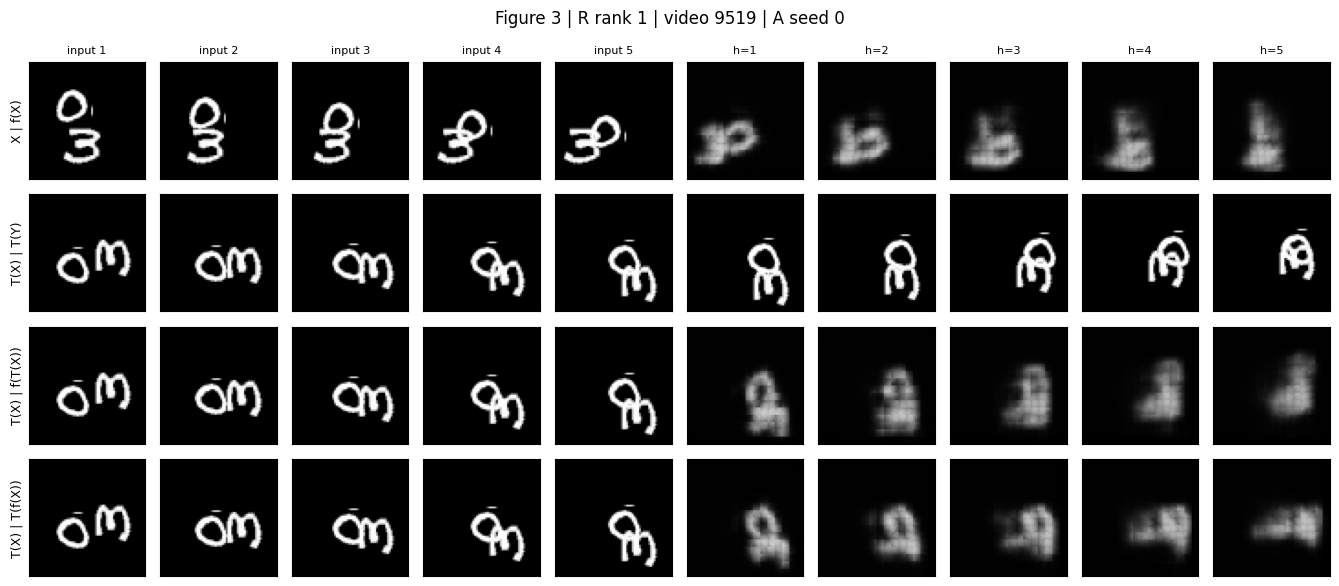

GIF path: `results/gifs/figure_3_R_1_video9519.gif`

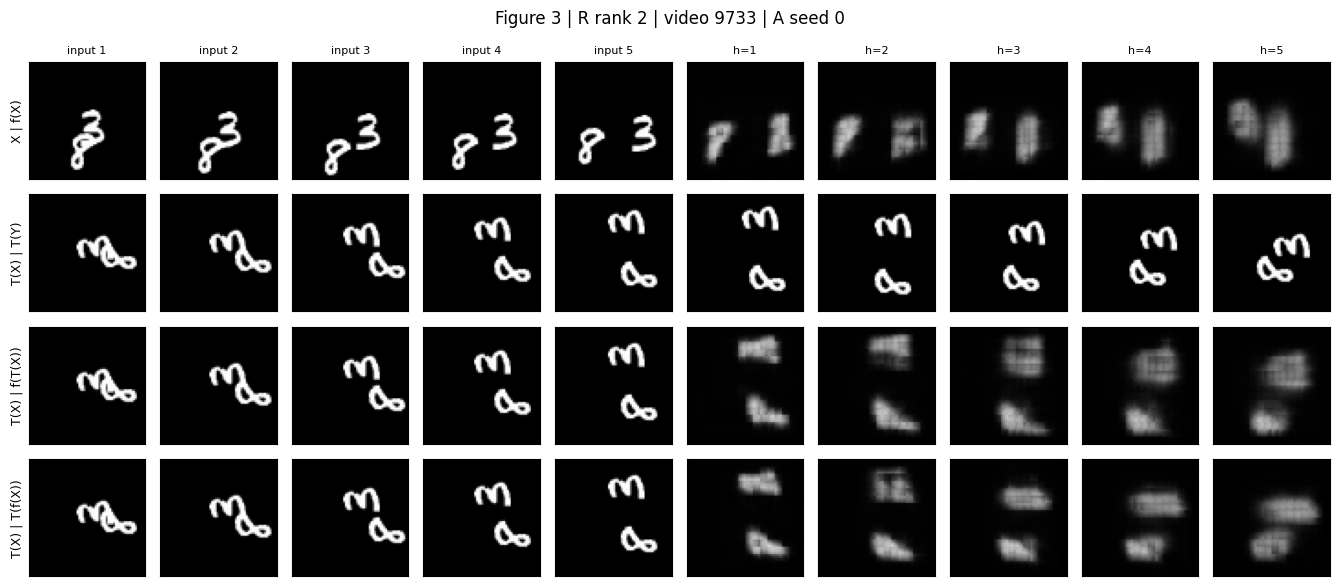

GIF path: `results/gifs/figure_3_R_2_video9733.gif`

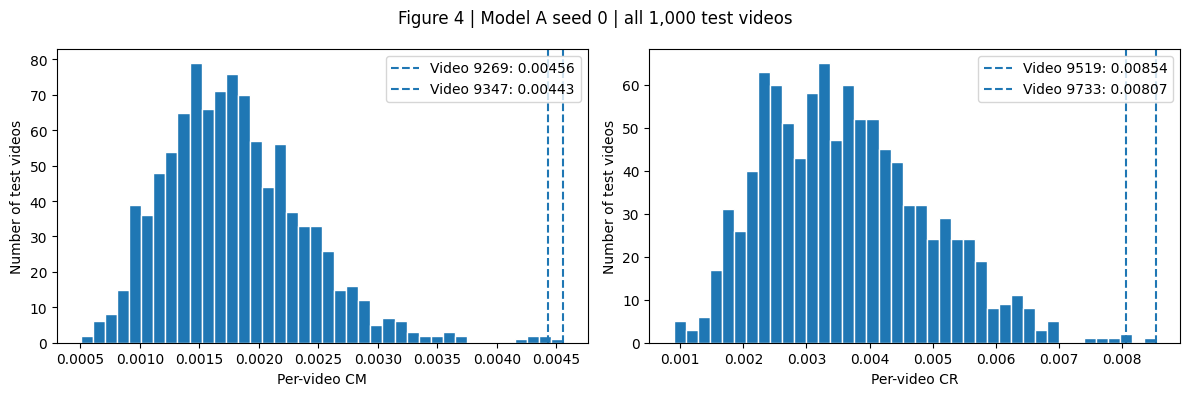

In [ ]:
def save_four_row_gif(futures,labels,title,path):
    rendered=[]
    for h in range(5):
        fig,axes=plt.subplots(4,1,figsize=(3.2,8))
        for r in range(4):
            axes[r].imshow(futures[r][h,0],cmap='gray',vmin=0,vmax=1)
            axes[r].set_title(labels[r],fontsize=9);axes[r].axis('off')
        fig.suptitle(f'{title}\nForecast horizon {h+1}');fig.tight_layout()
        fig.canvas.draw()
        rendered.append(np.asarray(fig.canvas.buffer_rgba())[...,:3].copy())
        plt.close(fig)
    imageio.mimsave(path,rendered,duration=600,loop=0)

def symmetry_panel(model,idx,g,title,png,gif):
    x,y,mask,pred=predict_video(model,idx)
    with torch.no_grad(): transformed_pred=model(transform(x,g).unsqueeze(0).to(DEVICE)).cpu()[0]
    tx=transform(x,g)
    futures=[pred,transform(y,g),transformed_pred,transform(pred,g)]
    rows=[torch.cat([x,futures[0]]),torch.cat([tx,futures[1]]),
          torch.cat([tx,futures[2]]),torch.cat([tx,futures[3]])]
    labels=['X | f(X)','T(X) | T(Y)','T(X) | f(T(X))','T(X) | T(f(X))']
    frame_grid(rows,labels,title,png,[f'input {h}' for h in range(1,6)]+[f'h={h}' for h in range(1,6)])
    save_four_row_gif(futures,labels,title,gif)
    display(Markdown(f'GIF path: `{gif.relative_to(ROOT)}`'))

base=read_evaluation('A',0,1)
FIG3_SELECTION={label:[int(base['ids'][i]) for i in np.argsort(-base['C'+label],kind='stable')[:2]] for label in ('M','R')}
(OUT/'figure3_selection.json').write_text(json.dumps(FIG3_SELECTION,indent=2))
a0=load_model('A',0)
for label,g in [('M',MIRROR),('R',ROTATION)]:
    for rank,idx in enumerate(FIG3_SELECTION[label],1):
        stem=f'figure_3_{label}_{rank}_video{idx}'
        symmetry_panel(a0,idx,g,f'Figure 3 | {label} rank {rank} | video {idx} | A seed 0',
                       OUT/'figures'/f'{stem}.png',OUT/'gifs'/f'{stem}.gif')

fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,label in zip(axes,('M','R')):
    values=base['C'+label];ax.hist(values,bins=40,edgecolor='white')
    for idx in FIG3_SELECTION[label]:
        value=values[np.where(base['ids']==idx)[0][0]]
        ax.axvline(value,linestyle='--',label=f'Video {idx}: {value:.3g}')
    ax.set(xlabel=f'Per-video C{label}',ylabel='Number of test videos');ax.legend()
fig.suptitle('Figure 4 | Model A seed 0 | all 1,000 test videos');fig.tight_layout()
fig.savefig(OUT/'figures'/'figure_4.png',dpi=180,bbox_inches='tight');plt.show()


### Q2.6

> Blank and Copy-last are exactly consistent under mirror and rotation. What does this say about reading C_T on its own, and why does E_T always have to be reported next to it?

**Answer:**

The consistency gap \(C_T\) only tells us whether the model gives similar predictions after a transformation. It does not tell us whether those predictions are correct.

Blank and Copy-last have \(C_T=0\), but their prediction errors \(E_T\) are still high. This means they are perfectly consistent but make poor predictions. Therefore, \(C_T\) must always be reported together with \(E_T\):

- \(C_T\) measures consistency.
- \(E_T\) measures correctness.

A model can be consistent and still be wrong.

### Q2.7

> Pick one video in Figure 3 where rows 3 and 4 disagree and describe precisely how the model’s account of the motion changes. For example, a digit goes the wrong way, gets lost, bounces too early or not at all, or blurs into something unrecognisable.

**Answer:**

For video **9519** in the rotation test, rows 3 and 4 disagree. In row 3, the model receives the rotated frames directly and predicts a blurry merged shape; the two digits are no longer clearly separated. In row 4, the model first predicts the original video and the prediction is then rotated, so the predicted shapes and positions are different. Thus, after rotation, the model changes its account of the motion and loses the separate identities of the digits instead of applying the same motion rule consistently.

### Q2.8

> Is rotation harder than mirroring for model A? Using your answers to Q2.1 and Q2.2, argue whether the difference comes from the motion or from the digits’ appearance.

**Answer:**

Yes, rotation is harder for Model A.

The rotation consistency gap and error are higher than the mirror values:

- C_R=0.00323 > C_M=0.00174
- E_R=0.0241 > E_M=0.0228.

From Figure 1, the training data already contains movement in many directions. Therefore, rotated movement itself should not be completely unfamiliar to the model. According to Q2.2, both mirroring and rotation change the digit’s appearance, but rotation changes it more strongly. Therefore, the higher rotation error is more likely caused by the changed digit appearance than by the motion.

### Faster motion
The model still generates five frames at 3×, but only the first two have ground truth. Do not score padded targets. The Figure 5 selection preview shows the union of all true frames that will appear across the three speeds.


**Table 4**

,Model,E2 @ 1x,E5 @ 1x,E2 @ 2x,E5 @ 2x,E2 @ 3x
0,A,"0.0188 (0.0188, 0.0188)","0.0221 (0.0223, 0.022)","0.0446 (0.0448, 0.0443)","0.0493 (0.0499, 0.0487)","0.0522 (0.0534, 0.0509)"
1,Copy-last,0.0548,0.0641,0.0661,0.0719,0.0703


Possible non-overlapping clips: [9021, 9026, 9029, 9038]


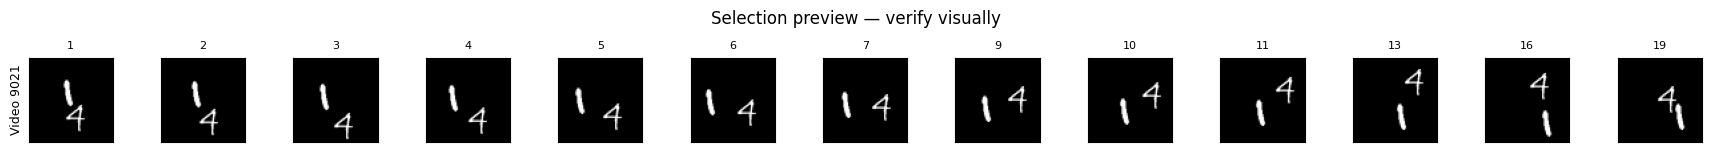

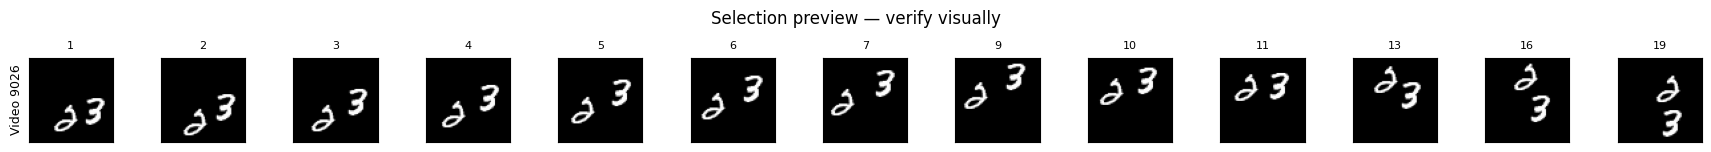

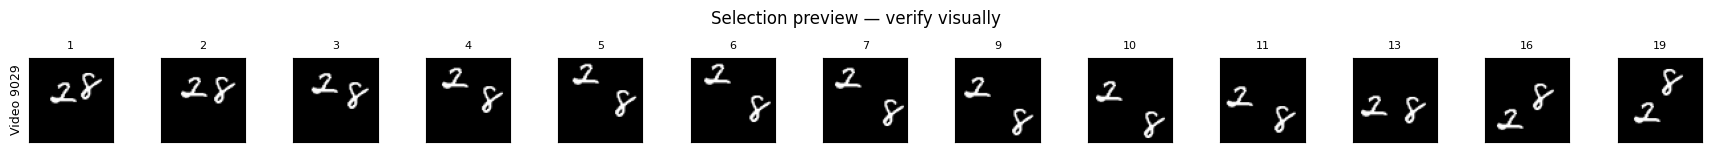

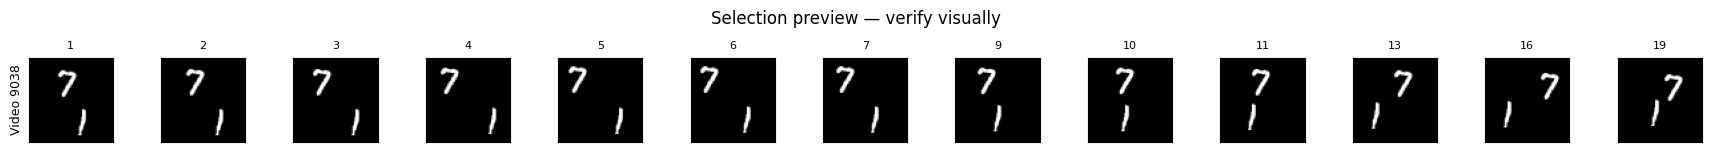

In [ ]:
for name in ('A','Copy-last'):
    for seed in (SEEDS if name=='A' else (0,)):
        model=load_model(name,seed) if name=='A' else Reference(name).to(DEVICE)
        for k in (2,3): save_evaluation(name,seed,k,evaluate(model,k))
        del model
rows=[]
for name in ('A','Copy-last'):
    row={'Model':name}; seeds=SEEDS if name=='A' else (0,)
    for k in (1,2,3):
        for metric in (('E2','E5') if k<3 else ('E2',)):
            vals=[error_summary(read_evaluation(name,s,k))[metric] for s in seeds]
            row[f'{metric} @ {k}x']=pair(vals) if name=='A' else fmt(vals[0])
    rows.append(row)
save_table(pd.DataFrame(rows),4)

NO_OVERLAP_CANDIDATES=suggest_candidates('no_overlap')
print('Possible non-overlapping clips:',NO_OVERLAP_CANDIDATES)
FIG5_TRUE_FRAMES=sorted({1+(j*k) for k in (1,2,3) for j in range(7)})
preview_candidates(NO_OVERLAP_CANDIDATES,FIG5_TRUE_FRAMES)


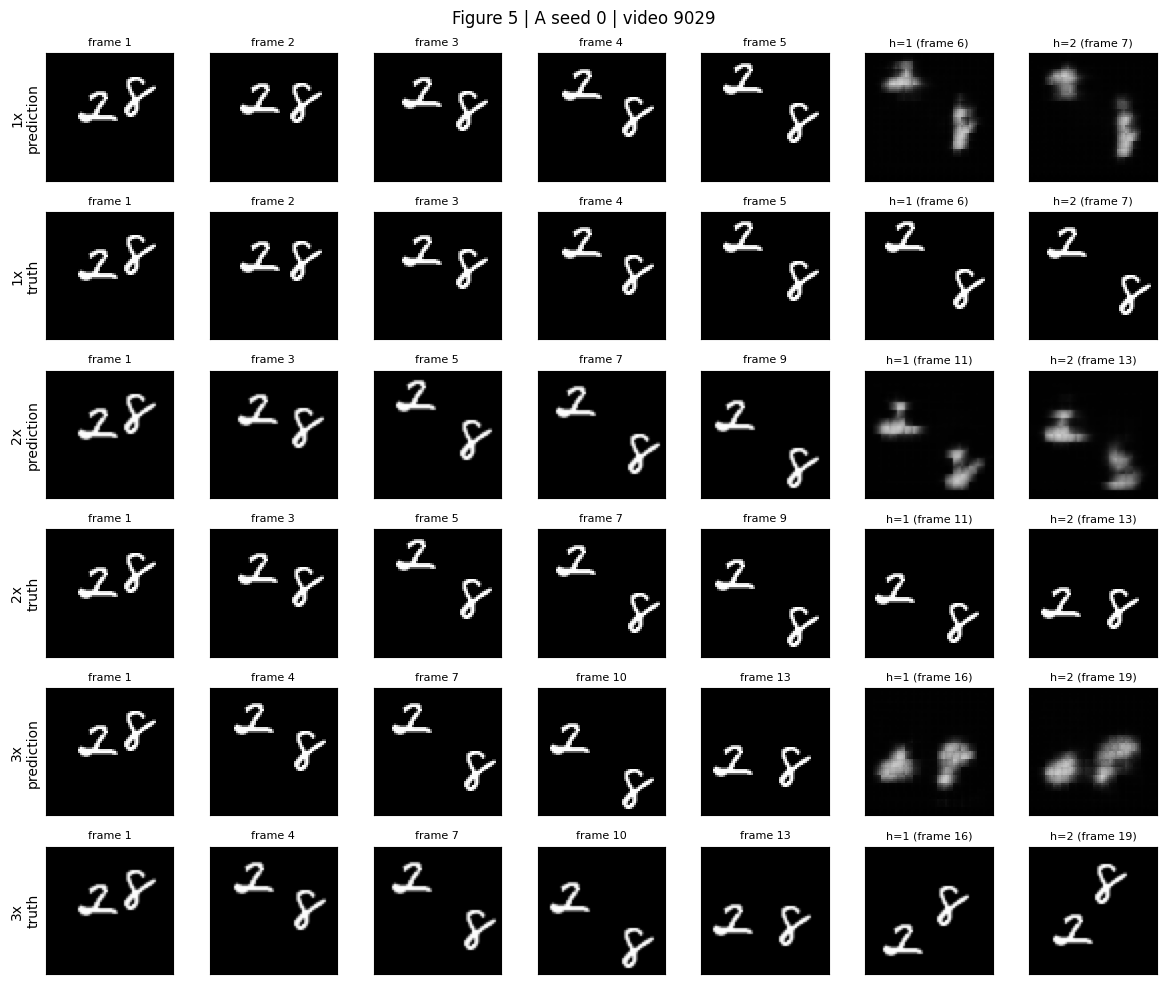

In [ ]:
FIG5_ID = 9029
FIG5_NO_OVERLAP_CONFIRMED = True
assert FIG5_ID in TEST_IDS and FIG5_NO_OVERLAP_CONFIRMED, 'Choose and verify a Figure 5 video first.'
(OUT/'figure5_selection.json').write_text(json.dumps({'id':FIG5_ID,'no_overlap_confirmed':True}))

def speed_panel(model,idx,title,path):
    fig,axes=plt.subplots(6,7,figsize=(12,10))
    for block,k in enumerate((1,2,3)):
        x,y,mask,pred=predict_video(model,idx,k)
        for sub,(future,label) in enumerate([(pred[:2],'prediction'),(y[:2],'truth')]):
            frames=torch.cat([x,future]);r=2*block+sub
            for c in range(7):
                ax=axes[r,c];ax.imshow(frames[c,0],cmap='gray',vmin=0,vmax=1)
                ax.set_xticks([]);ax.set_yticks([])
                ax.set_title(f'frame {1+c*k}' if c<5 else f'h={c-4} (frame {1+c*k})',fontsize=8)
                if c==0:ax.set_ylabel(f'{k}x\n{label}')
    fig.suptitle(title);fig.tight_layout();fig.savefig(path,dpi=180,bbox_inches='tight');plt.show()

speed_panel(load_model('A',0),FIG5_ID,f'Figure 5 | A seed 0 | video {FIG5_ID}',OUT/'figures'/'figure_5.png')


### Q2.9

> At what speed do model A’s predictions fall apart, and does this agree with the reach you estimated in Q2.3? If not, what did your estimate miss? Describe what the failure in Figure 5 looks like (blur, a digit that stalls, a duplicated digit, a digit that vanishes) and what each of these suggests the model is doing.

**Answer:**

Model A starts to break down at \(2x \) speed and becomes much worse at \(3x\). This agrees partly with the reach estimate. The estimated reach is 8 pixels per time step, while the typical movement is about 6.64 pixels at \(2x\) and 9.96 pixels at \(3x\). Therefore, \(3x\) clearly exceeds the estimated reach, but the model already struggles at \(2x\).

The estimate was an ideal architectural limit. It does not consider that Model A was trained only on \(1x\) videos, that movement can occur diagonally, or that the model may not use its entire theoretical reach effectively.

In Figure 5, the predictions at \(2x\) and \(3x\) become very blurry. The two digits merge into unclear shapes, especially in the future frames. This suggests that the model cannot accurately connect the digits’ previous locations with their new, more distant locations. It produces blurred guesses instead of clearly tracking each digit. The digits do not mainly stall or duplicate; their identities and positions become unclear.

### Q2.10

> From these results alone, can you tell whether the speed failure happens because fast motion never appeared in training, or because it is beyond the model’s reach? Propose an experiment that would tell the two apart.

**Answer:**

No. These results alone cannot tell us the exact reason for the failure. Model A was trained only on \(1x \) videos, so the faster motion may be unfamiliar. At the same time, faster movement may be beyond the model’s 8-pixel reach.

To separate these explanations, train the same Model A architecture using \(2x \) and \(3x \) videos. If the model improves after seeing fast motion, the failure was partly caused by unfamiliar training speeds. If it still fails, especially at \(3x \), the movement is probably beyond the model’s architectural reach. We can then train a model with a larger reach and compare it with the speed-trained model.

## 4. What Can Data Fix?
| Model | Architecture | Training speeds | Symmetry augmentation |
|---|---|---|---|
| A | Baseline | 1× | None |
| B | Baseline | 1× | Uniform from 8 square symmetries |
| C | Baseline | Uniform from 1×, 2×, 3× | None |
| D | Dilation 2 in both recurrent layers | Uniform from 1×, 2×, 3× | None |

D retains 480,784 parameters, below the 721,176 limit. Its longest two-convolution path reaches 4 folded cells per coordinate instead of 2. With four original pixels per folded cell, that is an axis-wise radius of 16 instead of 8 pixels. The furthest diagonal distances are respectively 16√2 and 8√2. Explain your chosen convention in Q2.3/Q2.12. Increased reach is not a performance guarantee; dilation samples a sparse neighbourhood.

This is a preselected design, not a design chosen using test performance. If you investigate alternatives, do so on validation videos only, document that search, freeze your choice, and use a fresh experiment folder to avoid stale checkpoints.


### Q2.11

> Before training B–D, predict in at most three sentences which model will fix which of the failures you found in Testing the Baseline. As with Q2.5, include this unedited in your report.

**Answer:**

I predict that Model B will improve Model A’s mirror and rotation performance because it trains with transformed digit appearances. Model C should improve performance at \(2x \) and \(3x \) speeds because it sees fast motion during training. If Model C still fails at high speeds, Model D should improve the results because its larger reach can connect positions that are farther apart.

In [ ]:
for name in ('B','C','D'):
    for seed in SEEDS:
        trained=train_model(name,seed)
        del trained
        if DEVICE.type=='cuda': torch.cuda.empty_cache()


B seed 0, epoch 1/30:   0%|          | 0/250 [00:00<?, ?it/s]

B/0: epoch 01, loss=0.046102, 14.4s


B seed 0, epoch 2/30:   0%|          | 0/250 [00:00<?, ?it/s]

B/0: epoch 02, loss=0.0396926, 14.1s


B seed 0, epoch 3/30:   0%|          | 0/250 [00:00<?, ?it/s]

...

D/1: epoch 28, loss=0.0303103, 68.1s


D seed 1, epoch 29/30:   0%|          | 0/250 [00:00<?, ?it/s]

D/1: epoch 29, loss=0.030176, 68.2s


D seed 1, epoch 30/30:   0%|          | 0/250 [00:00<?, ?it/s]

D/1: epoch 30, loss=0.0300594, 68.0s


In [ ]:
for name in ('A','B','C','D'):
    for seed in SEEDS:
        model=load_model(name,seed)
        for k in (1,2,3):
            save_evaluation(name,seed,k,evaluate(model,k,spatial=(k==1)))
        elapsed=inference_seconds(model)
        ck=trusted_load(checkpoint_path(name,seed))
        timing={'training_s_per_epoch':float(np.mean([h['seconds'] for h in ck['history']])),
                'inference_s_1000_videos':elapsed,'parameters':parameter_count(model),
                'inference_hardware':HARDWARE,'training_hardware_segments':ck['hardware_segments']}
        (OUT/'metrics'/f'{name}_seed{seed}_timing.json').write_text(json.dumps(timing,indent=2))
        del model

def comparison_table(labels,number,wrapped=False):
    rows=[]
    for label in labels:
        row={'Model':label}
        summaries=[error_summary(read_evaluation(label,s,1)) for s in SEEDS]
        for key in ('E5','CM','EM','CR','ER'):
            row[f'{key} @ 1x']=pair([v[key] for v in summaries],scientific=wrapped and key in ('CM','CR'))
        for k in (1,2,3):
            row[f'E2 @ {k}x']=pair([error_summary(read_evaluation(label,s,k))['E2'] for s in SEEDS])
        timings=[json.loads((OUT/'metrics'/f'{label}_seed{s}_timing.json').read_text()) for s in SEEDS]
        row['Parameters']=pair([v['parameters'] for v in timings],integer=True)
        row['Train seconds / epoch']=pair([v['training_s_per_epoch'] for v in timings])
        row['Inference seconds / 1000']=pair([v['inference_s_1000_videos'] for v in timings])
        rows.append(row)
    table=pd.DataFrame(rows);save_table(table,number);return table

table5=comparison_table(list('ABCD'),5)


**Table 5**

,Model,E5 @ 1x,CM @ 1x,EM @ 1x,CR @ 1x,ER @ 1x,E2 @ 1x,E2 @ 2x,E2 @ 3x,Parameters,Train seconds / epoch,Inference seconds / 1000
0,A,"0.0221 (0.0223, 0.022)","0.00174 (0.0018, 0.00169)","0.0228 (0.023, 0.0227)","0.00323 (0.00363, 0.00283)","0.0241 (0.0243, 0.0239)","0.0188 (0.0188, 0.0188)","0.0446 (0.0448, 0.0443)","0.0522 (0.0534, 0.0509)","480,784 (480,784, 480,784)","13.4 (13.3, 13.4)","0.398 (0.393, 0.403)"
1,B,"0.0226 (0.0235, 0.0217)","0.00122 (0.00114, 0.0013)","0.0226 (0.0234, 0.0217)","0.00153 (0.00151, 0.00156)","0.0225 (0.0235, 0.0215)","0.019 (0.0199, 0.018)","0.0449 (0.0447, 0.0451)","0.0525 (0.0528, 0.0521)","480,784 (480,784, 480,784)","14 (13.9, 14)","0.397 (0.393, 0.401)"
2,C,"0.0279 (0.0284, 0.0275)","0.00107 (8.87e-04, 0.00126)","0.0281 (0.0285, 0.0277)","0.00193 (0.0016, 0.00226)","0.0289 (0.0292, 0.0285)","0.024 (0.0242, 0.0237)","0.0295 (0.0296, 0.0293)","0.0338 (0.0339, 0.0338)","480,784 (480,784, 480,784)","13.5 (13.5, 13.6)","0.4 (0.397, 0.402)"
3,D,"0.0284 (0.0284, 0.0284)","0.00108 (0.00115, 0.00101)","0.0287 (0.0287, 0.0287)","0.00197 (0.00199, 0.00195)","0.0294 (0.0294, 0.0294)","0.0262 (0.0262, 0.0261)","0.029 (0.0289, 0.0291)","0.0313 (0.0313, 0.0314)","480,784 (480,784, 480,784)","68 (68, 67.9)","0.858 (0.858, 0.858)"


### Q2.12

> Describe model D and estimate its reach the same way you did in Q2.3, showing that it is strictly larger than model A’s.

**Answer:**

Model D uses the same overall architecture as Model A, but its two \(3 x 3\) ConvLSTM convolutions use dilation 2. With dilation 2, each convolution can reach two cells in the \(16 x 16\) folded grid instead of one. Since there are two ConvLSTM layers, the longest path can travel \(2+2=4\) grid cells. Each grid cell represents 4 original pixels, so Model D’s reach is \(4x 4=16\) original pixels per time step. This is strictly larger than Model A’s 8-pixel reach. Both models still have 480,784 parameters because dilation changes the spacing of the kernel elements without adding more weights. The results also show that Model D is slower during training and inference, with about 68 seconds per epoch and 0.858 seconds per 1,000 videos.

### Q2.13

> Label each failure from Testing the Baseline as appearance, unfamiliar motion, or architectural reach, citing the comparison in Table 5 that supports each label. In particular, if model C still does badly at 3× while model D does well, what does that tell you, and why can’t more training data carry information further than the architecture allows?

**Answer:**

The mirror and rotation failures are mainly related to digit appearance. Model B has the same architecture and training speed as Model A, but it uses symmetry augmentation. Its rotation consistency gap decreases from \(0.00323\) to \(0.00153\), and its rotation error decreases from \(0.0241\) to \(0.0225\). This suggests that training on transformed digit appearances helps the model handle rotated and mirrored digits.

The fast-motion failure is partly caused by unfamiliar motion. Compared with Model A, Model C is trained using \(1x \), \(2x \), and \(3 x\) windows. Its \(E2\) error improves from \(0.0446\) to \(0.0295\) at \(2x \), and from \(0.0522\) to \(0.0338\) at \(3x \). This shows that exposing the model to faster motion helps it learn those motion patterns.

There is also evidence of an architectural reach problem. Models C and D use the same speed-augmented training, but D has a larger reach. At \(3x \), D performs better than C, reducing \(E2\) from \(0.0338\) to \(0.0313\). This suggests that some remaining failure is caused by limited reach. More training data cannot make information travel farther within one update because the distance information can move is determined by the convolution kernels, dilation, and number of layers. To connect positions farther apart, the architecture itself must provide a larger reach.

### Q2.14

> Did any of these changes cost accuracy on the original 1× clips? If so, was it worth it?

**Answer:**

Yes, the changes reduced accuracy on the original \(1x\) clips. Model B’s error increased slightly from \(0.0221\) to \(0.0226\), but its mirror and rotation consistency improved substantially, so this small cost was worthwhile. Models C and D had larger errors at \(1x\), \(0.0279\) and \(0.0284\), respectively, because they trained on multiple speeds. However, they performed much better at faster speeds. Model D reduced the \(3x\) error from Model A’s \(0.0522\) to \(0.0313\). Therefore, the loss in normal-speed accuracy was worthwhile if the system needs to handle fast motion, although Model D required more computation.


## 5. The Final Model
For each model, predict under all eight square symmetries, undo each transformation and average:
$$\bar f(X)=\frac18\sum_{g\in G}g^{-1}f(gX).$$
No retraining or extra trainable parameters are introduced. Sequential passes limit GPU memory; all eight passes and transformations are included in inference timing. Both wrapped B and wrapped D are evaluated with both seeds. **The final model is wrapped D**, so Table 6 does not need a duplicate final-model row.




In [ ]:
for base_name in ('B','D'):
    label=f'Sym-{base_name}'
    for seed in SEEDS:
        wrapped=Symmetrised(load_model(base_name,seed)).to(DEVICE).eval()
        for k in (1,2,3):
            result=evaluate(wrapped,k,spatial=(k==1))
            save_evaluation(label,seed,k,result)
            if k==1:
                print(label,seed,'CM=',result['CM'].mean(),'CR=',result['CR'].mean())
                if max(result['CM'].max(),result['CR'].max())>1e-10:
                    print('Unexpectedly large symmetry residual: inspect transforms, eval mode and precision.')
        underlying=json.loads((OUT/'metrics'/f'{base_name}_seed{seed}_timing.json').read_text())
        timing={**underlying,'inference_s_1000_videos':inference_seconds(wrapped),
                'parameters':parameter_count(wrapped),'inference_hardware':HARDWARE}
        (OUT/'metrics'/f'{label}_seed{seed}_timing.json').write_text(json.dumps(timing,indent=2))
        del wrapped

table6=comparison_table(['Sym-B','Sym-D'],6,wrapped=True)


Sym-B 0 CM= 8.761929e-17 CR= 7.1244034e-17
Sym-B 1 CM= 9.650796e-17 CR= 7.78228e-17
Sym-D 0 CM= 5.420222e-17 CR= 4.241571e-17
Sym-D 1 CM= 5.156892e-17 CR= 4.048637e-17


**Table 6**

,Model,E5 @ 1x,CM @ 1x,EM @ 1x,CR @ 1x,ER @ 1x,E2 @ 1x,E2 @ 2x,E2 @ 3x,Parameters,Train seconds / epoch,Inference seconds / 1000
0,Sym-B,"0.0219 (0.0229, 0.021)","9.21e-17 (8.76e-17, 9.65e-17)","0.0219 (0.0229, 0.021)","7.45e-17 (7.12e-17, 7.78e-17)","0.0219 (0.0229, 0.021)","0.0185 (0.0195, 0.0176)","0.0442 (0.0442, 0.0442)","0.0515 (0.0522, 0.0508)","480,784 (480,784, 480,784)","14 (13.9, 14)","3.89 (4.15, 3.64)"
1,Sym-D,"0.0283 (0.0283, 0.0283)","5.29e-17 (5.42e-17, 5.16e-17)","0.0283 (0.0283, 0.0283)","4.15e-17 (4.24e-17, 4.05e-17)","0.0283 (0.0283, 0.0283)","0.0261 (0.0262, 0.026)","0.0289 (0.0288, 0.0289)","0.0311 (0.0311, 0.0311)","480,784 (480,784, 480,784)","68 (68, 67.9)","7.38 (7.42, 7.35)"


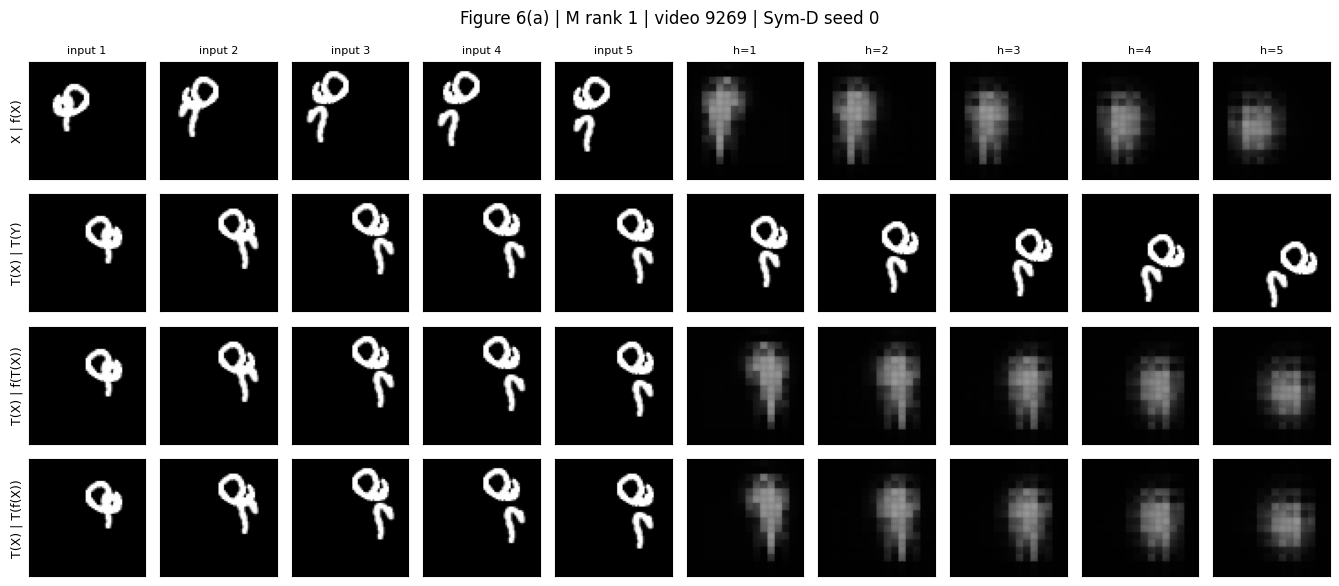

GIF path: `results/gifs/figure_6a_M_1_video9269.gif`

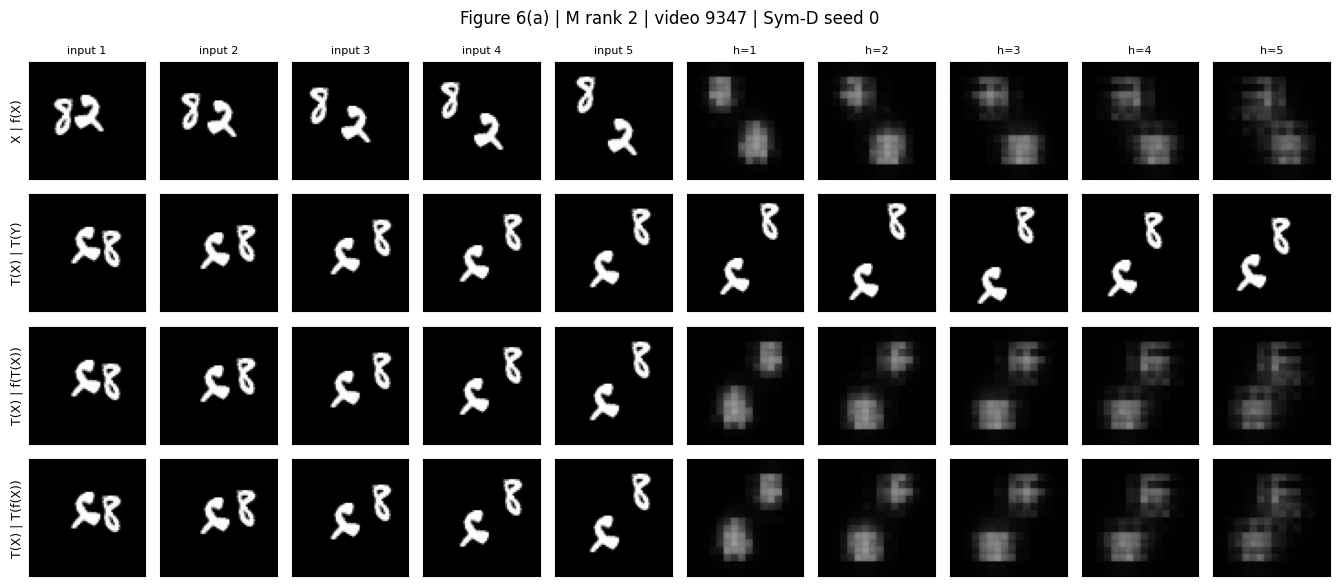

GIF path: `results/gifs/figure_6a_M_2_video9347.gif`

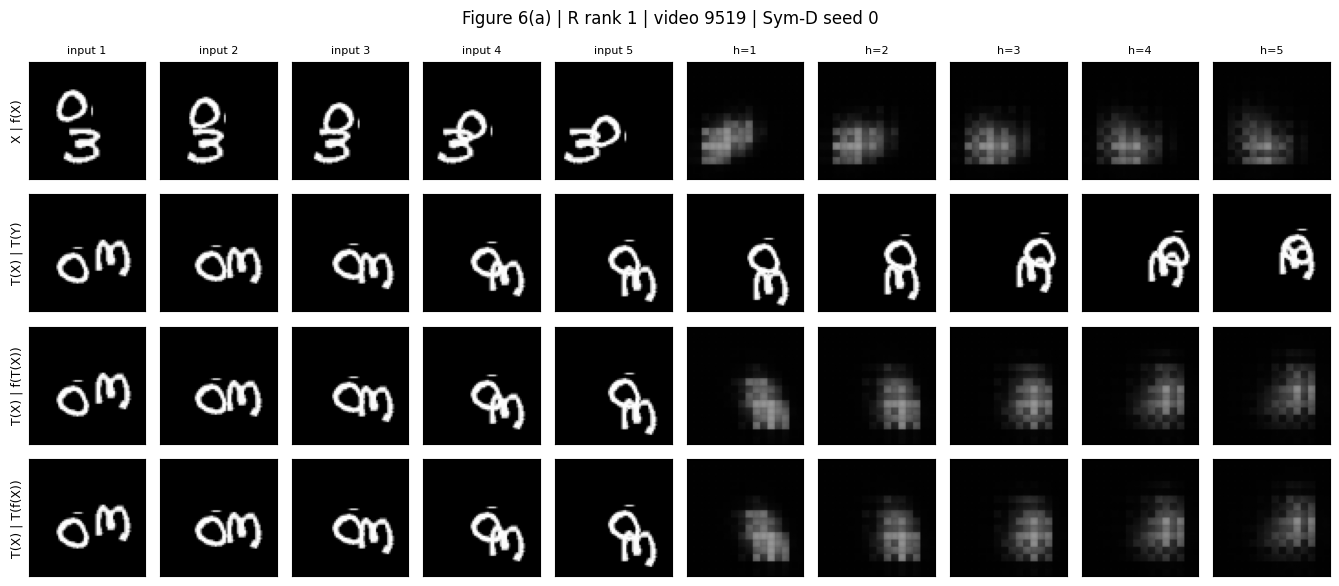

GIF path: `results/gifs/figure_6a_R_1_video9519.gif`

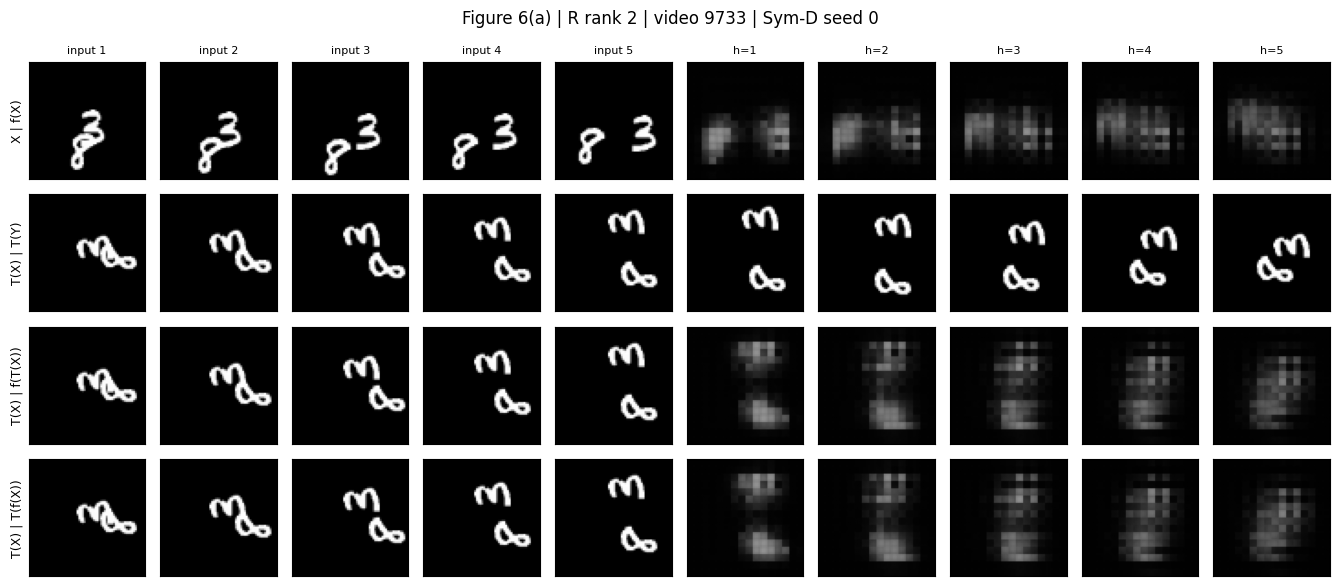

GIF path: `results/gifs/figure_6a_R_2_video9733.gif`

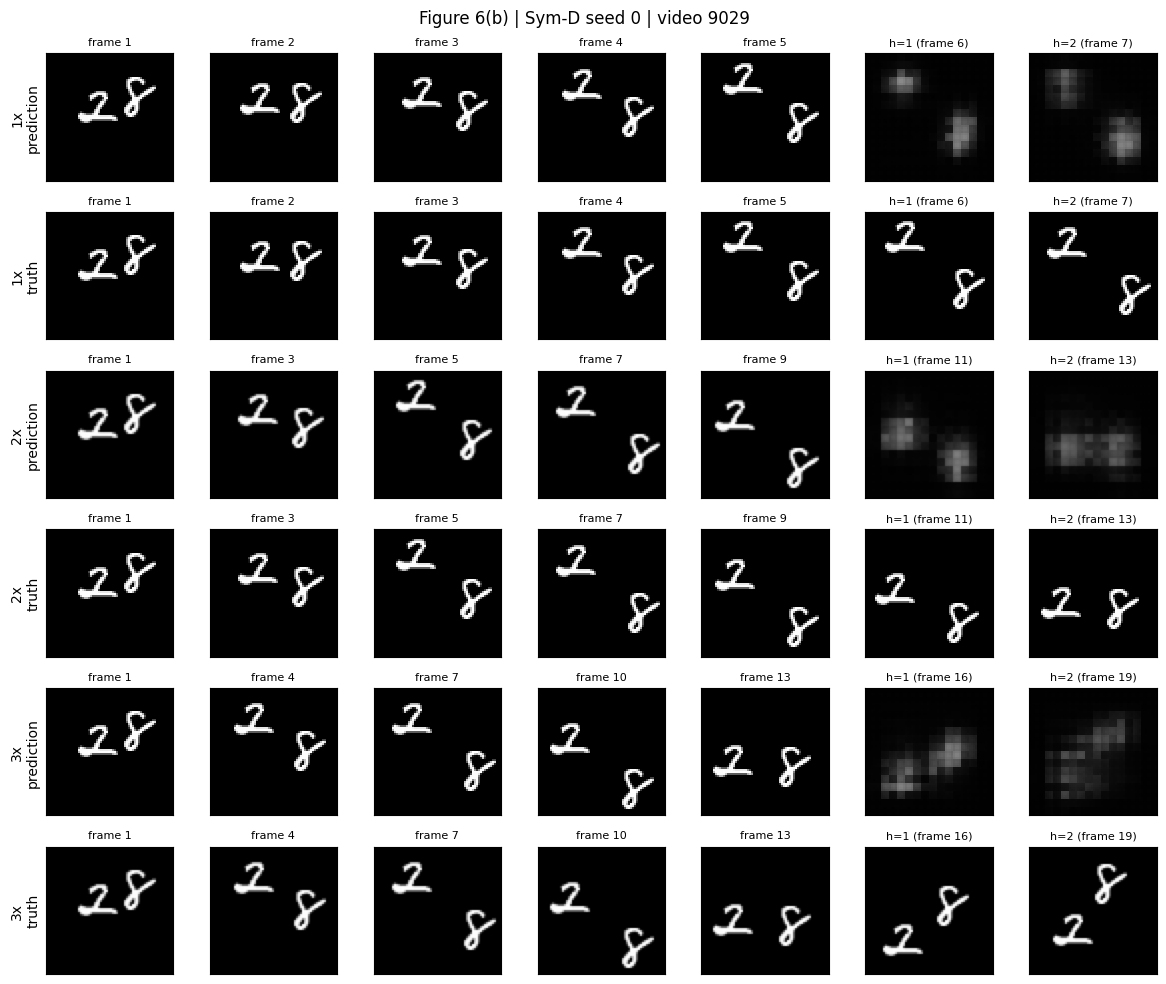

175

In [ ]:
selection=json.loads((OUT/'figure3_selection.json').read_text())
speed_id=json.loads((OUT/'figure5_selection.json').read_text())['id']
final_model=Symmetrised(load_model('D',0)).to(DEVICE).eval()
for label,g in [('M',MIRROR),('R',ROTATION)]:
    for rank,idx in enumerate(selection[label],1):
        stem=f'figure_6a_{label}_{rank}_video{idx}'
        symmetry_panel(final_model,idx,g,f'Figure 6(a) | {label} rank {rank} | video {idx} | Sym-D seed 0',
                       OUT/'figures'/f'{stem}.png',OUT/'gifs'/f'{stem}.gif')
speed_panel(final_model,speed_id,f'Figure 6(b) | Sym-D seed 0 | video {speed_id}',OUT/'figures'/'figure_6b.png')
(OUT/'final_model.json').write_text(json.dumps({'model':'Sym-D','underlying':'D','figure_seed':0,
 'reason':'D increases reach; group averaging guarantees square-symmetry equivariance. No optional D+B run.'},indent=2))


### Q2.15

> Compare symmetry that is learned (model B) with symmetry that is built in (the symmetrised models) in terms of consistency, accuracy on original and transformed clips, and inference cost. Which one is exact, and why? Averaging eight predictions can also blur them; when would you expect built-in symmetry to hurt accuracy, and did it here?

**Answer:**

Model B learns symmetry through data augmentation, so it becomes more consistent than Model A, but its consistency is not exact. Its gaps are \(C_M=0.00122\) and \(C_R=0.00153\). The symmetrised models have gaps close to zero, around \(10^{-17}\), because they explicitly apply all eight transformations, undo them, and average the results. Therefore, the built-in symmetry is exact up to floating-point error.

Sym-B also has slightly better original accuracy than B: its \(E5\) is \(0.0219\), compared with B’s \(0.0226\). Sym-D has almost the same accuracy as D, with \(E5=0.0283\) compared with \(0.0284\). Thus, averaging did not hurt accuracy in this experiment. It could hurt when the eight transformed predictions are very different or poorly aligned, because averaging them may produce blurry digits. The main disadvantage is inference cost: Sym-B takes about \(3.89\) seconds compared with B’s \(0.397\) seconds, and Sym-D takes \(7.38\) seconds compared with D’s \(0.858\) seconds. This is expected because the symmetrised model performs eight prediction passes instead of one.

### Q2.16

> Go back to the video you discussed in Q2.7. Does the final model now get it right (Figure 6), and which change fixed which part of the failure?

**Answer:**

For the same video from Q2.7, the final model, Sym-D, makes rows 3 and 4 agree much more closely. The built-in symmetry averaging fixes the inconsistency caused by rotating the input: predicting after rotation and rotating the original prediction now produce almost identical outputs.

However, the final model may still produce blurry predictions or imperfect digit shapes, because symmetry consistency does not guarantee correct forecasting. Model D’s larger reach mainly helps with faster motion, while the symmetrisation step fixes the disagreement caused by the rotated appearance. Therefore, the final model fixes the model’s inconsistent response to rotation, but it may not completely recover the true digit motion or appearance

### Q2.17

> Final verdict (150 words max). Did your final model learn motion? What evidence would convince a skeptic, and what is one test it still has not passed?

**Answer:**

The final model learned a useful motion pattern, but not perfectly. Model A performed better than Blank and Copy-last, showing that it learned more than simply producing empty frames or repeating the last frame. Models C and D improved performance on faster videos, and D’s larger reach reduced the \(3x \) error further. The final Sym-D model also achieved almost zero mirror and rotation consistency gaps, showing that its predictions respond consistently to these transformations. These results would convince a skeptic that the model learned transferable motion rather than only memorizing the original videos. However, its predictions still become blurry and its normal-speed error is higher than Model A’s. It has also not been tested on accelerating digits, different bounce rules, or completely new motion patterns. Therefore, it learned constant-speed motion in this dataset, but its ability to generalize to more complex motion remains unproven.

In [ ]:
required=[OUT/'tables'/f'table_{n}.csv' for n in range(1,7)]
required += [OUT/'figures'/f'figure_{n}.png' for n in (1,2,4,5)]
required += [OUT/'figures'/'figure_6b.png', OUT/'figure3_selection.json',OUT/'figure5_selection.json']
missing=[str(p.relative_to(ROOT)) for p in required if not p.exists()]
for prefix in ('figure_3_','figure_6a_'):
    if len(list((OUT/'gifs').glob(prefix+'*.gif')))!=4:
        missing.append(prefix+'*: expected four GIFs')
if missing: print('Still missing:',*missing,sep='\n- ')
else: print('All required table and figure groups are present. Check answers and captions manually.')
manifest={'protocol_version':PROTOCOL_VERSION,'hardware':HARDWARE,'missing_outputs':missing,
          'created_utc':datetime.now(timezone.utc).isoformat(),
          'note':'Experimental outputs only; save and share the executed notebook separately for written answers.'}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
import zipfile
bundle=ROOT/'Q2_results_for_review.zip'
with zipfile.ZipFile(bundle,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for directory in (OUT,ROOT/'predictions'):
        for path in directory.rglob('*'):
            if path.is_file(): archive.write(path,path.relative_to(ROOT))
print('Share this results bundle:',bundle)
print('Also save your executed notebook to preserve all answers and displayed outputs.')


All required table and figure groups are present. Check answers and captions manually.
Share this results bundle: /content/motion_or_memory/Q2_results_for_review.zip
Also save your executed notebook to preserve all answers and displayed outputs.


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/motion_or_memory",
    "zip",
    root_dir="/content",
    base_dir="motion_or_memory"
)
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>